<div style="text-align:center; border-radius:15px 50px; padding:22px; color:white; background-color:#000080; font-family:Pacifico">
<h1 style="color:white; margin:0; font-size:230%">Daraz Top Sales Products</h1>
<h3 style="color:#c9d4ff; margin-top:10px; font-family:Arial">Watches, Bags and Accessories &nbsp;|&nbsp; PRG-330 Final Project</h3>
<p style="color:#ffffff; font-family:Arial; font-size:110%; margin-top:16px; margin-bottom:0">
<b>Team:</b> &nbsp; Prashant &nbsp;&middot;&nbsp; Ananta &nbsp;&middot;&nbsp; Manish
</p>
</div>

### How we divided the presentation

We kept one continuous Daraz analysis, but divided the presentation so each person has a clear section.

| Part | What it covers | Presented by |
| :---- | :---- | :---- |
| **Part 1** | Introduction, dataset source, file loading, data types and understanding the raw data (Modules 1 to 5) | **Prashant** |
| **Part 2** | Data cleaning, functions, loops, conditions, price groups and Pandas analysis (Modules 6 to 8) | **Prashant & Ananta** |
| **Part 3** | Main visual analysis and interpretation (Module 9) | **Prashant & Ananta & Manish** |
| **Part 4** | Major findings, limitations and conclusion | **Manish** |

The notebook stays as one project. The Python concepts from class are shown where they are naturally used in the analysis rather than as separate artificial examples.

## Course concepts used in this project

The concepts from class are **not separate practice examples**. They are used directly in the Daraz analysis below.

| Course concept | Where it is demonstrated in this notebook |
| :--- | :--- |
| **File input / output** | Module 4 loads the CSV with `pd.read_csv()`; Module 6 exports the cleaned data with `to_csv()` |
| **Variables & data types** | Module 5 — `shape`, `columns`, `info()` and conversion from text to numeric types |
| **Strings & lists** | Module 6 — string cleaning plus lists that collect cleaned results |
| **Operators** | Module 6 — subtraction and division calculate discount amount and discount percentage |
| **Conditional statements** | Modules 6 & 8 — `if / else` handles `K Sold`, missing values and price groups |
| **Loops** | Modules 6 & 8 — `for` loops clean sold counts and process category/price-group logic |
| **Functions** | Modules 6 & 8 — `sold_to_number()` and `price_group()` apply reusable logic |
| **Pandas** | Modules 4–7 — loading, cleaning, grouping, aggregation and correlation |
| **NumPy** | Module 7 — arrays, percentiles/IQR, boolean comparison and correlation verification |
| **Matplotlib** | Module 9 — category, distribution and relationship visualizations |

> **Important:** Every concept above is used on the actual project data. We do not add unrelated classroom examples just to show syntax.

# <div style="text-align:center; border-radius:15px 50px; padding:12px; color:white; margin:0; font-size:150%; font-family:Pacifico; background-color: #000080; overflow:hidden"><b>Part 1: introduction and dataset</b><div style="font-family:Arial; font-size:58%; color:#d8dcff; margin-top:8px">presented by Prashant</div></div>

### Module 1: project introduction

**What we are doing.** We are analysing products sold on **Daraz Pakistan** using a 2024 dataset of top-selling watches, bags and accessories.

**Why we chose this dataset.** Online shopping is familiar, but the dataset is not already analysis-ready. Prices are stored as text, ratings look like `4.6/5`, sold counts look like `6K Sold`, and the voucher column mixes different offer formats. That gives us a realistic reason to use the Python concepts from class for cleaning, grouping, comparison and visualization.

**What we want to find out.**

* which categories have the most product records
* which categories are typically expensive or cheap
* which categories have higher reported sold counts
* whether price, star rating, rating count or discount percentage are related to sold count
* whether products with vouchers or free-delivery offers show different sales patterns
* what the visualizations reveal that is difficult to see from tables alone

Because this is a snapshot dataset, our results describe **associations in this dataset**. They do not prove that price, vouchers, delivery or any other feature causes sales.

### Module 2: dataset source and description

**Where it came from.**

| | |
| :---- | :---- |
| Name | Daraz Top Sales Products Dataset 2024 |
| Source | Kaggle, uploaded by muhammadmurtazasani |
| Link | https://www.kaggle.com/datasets/muhammadmurtazasani/daraz-top-sales-products-dataset-2024 |
| File we used | `Watches Bags Accessories.csv` |
| Size | 1078 rows and 11 columns |

**What the columns mean.**

* **Title** is the product name shown on the listing
* **Rating in Stars** is the star rating, but written as text like `4.6/5`
* **Rating Count** is how many people rated the product
* **Sold Count** is how many were sold, written as `452 Sold` or `6K Sold`
* **Voucher** is any voucher offer on the product, and it is the messiest column
* **Delivery** says either `Free Delivery` or just `0`
* **Currency** says `Rs.` on every single row
* **Current Price** is what the product sells for now
* **Original Price** is the price before the discount, written as `Rs. 520`
* **Category** is the type of product, and there are 7 of them
* **Link** is the web address of the product

**Which country is this?** Every link in the file points to `www.daraz.pk`, so this is the
Pakistani site and the prices are in Pakistani Rupees. We checked this rather than assuming,
because Daraz runs separate sites for Pakistan, Bangladesh, Nepal and Sri Lanka and the
currency is different in each one.

### Module 3: import libraries

> **Course concepts visible here:** libraries/modules, `import`, pandas, NumPy and Matplotlib.

We use **pandas** for loading, cleaning, grouping and tabular analysis, **NumPy** for numerical array/statistical operations, and **Matplotlib** for visualization.

Other Python concepts from class appear naturally later: variables store analysis results, arithmetic operators calculate discounts, conditions make decisions, functions handle reusable cleaning logic, and loops process real dataset values.

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

### Module 4: file input — load the dataset

> **Course concepts:** file input, variables and a pandas DataFrame.

`pd.read_csv()` is the file-input step of the project. It reads the CSV file and turns it into a pandas DataFrame stored in the variable `df`. We use `head()` immediately afterward to confirm that the file loaded correctly and to inspect the raw format before changing anything.

In [104]:
df = pd.read_csv("Watches Bags Accessories.csv")
df.head()

,Title,Rating in Stars,Rating Count,Sold Count,Voucher,Delivery,Currency,Current Price,Original Price,Link,Category
0,Yfashion Cartoon Electronic Watch Life Water...,4.6/5,707,6K Sold,0,Free Delivery,Rs.,287,Rs. 520,//www.daraz.pk/products/y-led-3-i258744118-s14...,Kids Watches
1,"100% Imported LED watch for men , boys and Kid...",4.3/5,293,1K Sold,0,0,Rs.,270,Rs. 999,//www.daraz.pk/products/100-led-2023-i40167553...,Kids Watches
2,1 Cartoon Characters Analog Wrist Watch For Ki...,4.5/5,57,452 Sold,0,Free Delivery,Rs.,225,Rs. 750,//www.daraz.pk/products/1-i423737473-s20070599...,Kids Watches
3,M3 Touch LED Bracelet Digital Watch Band Good ...,4.6/5,51,332 Sold,0,Free Delivery,Rs.,160,Rs. 299,//www.daraz.pk/products/m3-led-led-i432456407-...,Kids Watches
4,led Watches For Boys and Girls and kids,4.4/5,54,476 Sold,0,Free Delivery,Rs.,198,Rs. 300,//www.daraz.pk/products/led-i398157365-s192654...,Kids Watches


# <div style="text-align:center; border-radius:15px 50px; padding:12px; color:white; margin:0; font-size:150%; font-family:Pacifico; background-color: #191970; overflow:hidden"><b>Part 1 continued: understanding the data</b><div style="font-family:Arial; font-size:58%; color:#d8dcff; margin-top:8px">presented by Prashant</div></div>

### Module 5: data types and understanding the dataset

> **Course concepts visible here:** variables, strings/text, numeric data types, missing values and DataFrame inspection.

Before cleaning, we inspect the size, column names, data types, missing values and examples of the raw values. This is where the **data-type concept** becomes important: many columns that should be numeric are stored as `object` text, so calculations will not work until we convert them correctly.

In [105]:
# how many rows and columns do we have
df.shape

(1078, 11)

In [106]:
# what are the columns called
df.columns

Index(['Title', 'Rating in Stars', 'Rating Count', 'Sold Count', 'Voucher',
       'Delivery', 'Currency', 'Current Price', 'Original Price', 'Link',
       'Category'],
      dtype='object')

`info()` is the most useful command here because it shows the data type of every column and
how many values are filled in, both at the same time.

In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1078 entries, 0 to 1077
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Title            1078 non-null   object
 1   Rating in Stars  1078 non-null   object
 2   Rating Count     1078 non-null   int64 
 3   Sold Count       1044 non-null   object
 4   Voucher          1078 non-null   object
 5   Delivery         1078 non-null   object
 6   Currency         1078 non-null   object
 7   Current Price    1078 non-null   object
 8   Original Price   1010 non-null   object
 9   Link             1078 non-null   object
 10  Category         1078 non-null   object
dtypes: int64(1), object(10)
memory usage: 92.8+ KB


**What we found.** Only `Rating Count` is stored as a number. Every other column is `object`,
which in pandas means text. This is the main problem with the dataset and it is what most of
our cleaning is about.

In [108]:
df.describe()

,Rating Count
count,1078.000000
mean,202.360853
std,429.747239
min,0.000000
25%,25.000000
50%,68.000000
75%,184.750000
max,5553.000000


`describe()` normally gives the average, minimum and maximum of every numeric column. Here it
only shows one column, which proves the point above. Pandas does not see the prices or the
ratings as numbers yet, so it refuses to do any maths on them.

In [109]:
# how many products are in each category
df["Category"].value_counts()

Category
Womens Bags           200
Mens Accessories      160
Mens Watches          160
Womens Watches        160
Kids Watches          158
Mens Bags             120
Womens Accessories    120
Name: count, dtype: int64

In [110]:
# look at the messy looking columns before deciding what to do with them
print(df["Rating in Stars"].unique()[:8])
print(df["Sold Count"].unique()[:8])
print(df["Original Price"].unique()[:5])
print(df["Delivery"].unique())
print(df["Currency"].unique())

['4.6/5' '4.3/5' '4.5/5' '4.4/5' '3.8/5' '4/5' '3.6/5' '3.9/5']
['6K Sold' '1K Sold' '452 Sold' '332 Sold' '476 Sold' '689 Sold' '2K Sold'
 '404 Sold']
['Rs. 520' 'Rs. 999' 'Rs. 750' 'Rs. 299' 'Rs. 300']
['Free Delivery' '0']
['Rs.']


**What this tells us.**

* `Currency` says `Rs.` on all 1078 rows, so it carries no information at all
* `Delivery` uses `0` instead of writing something like "no free delivery", which is
  confusing to read
* the ratings, prices and sold counts all have text mixed into them

In [111]:
# the voucher column is the messiest one, so we look at all of its values
df["Voucher"].value_counts()

Voucher
0              922
3 Vouchers      52
4 Vouchers      33
6 Vouchers      19
2 Vouchers       9
5 Vouchers       8
7 Vouchers       7
8 Vouchers       5
Rs.1500 Off      5
Rs.5 Off         4
9 Vouchers       3
Rs.500 Off       3
Rs.20 Off        2
Rs.70 Off        2
5% Off           1
3% Off           1
Rs.120 Off       1
Rs.100 Off       1
Name: count, dtype: int64

**The problem with `Voucher`.** Three completely different things are stored in this one
column. Some rows count vouchers (`3 Vouchers`), some give an amount off (`Rs.1500 Off`),
some give a percentage (`5% Off`), and most are just `0`.

These cannot be compared with each other. Three vouchers is not bigger or smaller than
Rs 1500 off, they are different kinds of thing. Ananta explains in Module 6 what we decided
to do about it.

# <div style="text-align:center; border-radius:15px 50px; padding:12px; color:white; margin:0; font-size:150%; font-family:Pacifico; background-color: #4B0082; overflow:hidden"><b>Part 2: cleaning the data</b><div style="font-family:Arial; font-size:58%; color:#d8dcff; margin-top:8px">presented by Prashant</div></div>

### Module 6: data cleaning with functions, loops, conditions and operators

> **Course concepts visible here:** functions, parameters/return values, `if / else`, `for` loops, comparison checks, string operations, lists, arithmetic operators, type conversion and file output.

From Module 5, the main problems are:

1. repeated product records need to be identified before the product link is removed
2. `Currency` is identical on every row and `Link` is only needed for identifying repeated listings
3. `Rating in Stars` is text like `4.6/5`, and `0` is used for products with no ratings
4. `Current Price` and `Original Price` are text
5. `Sold Count` is text like `6K Sold`
6. `Delivery` uses `0` to mean the listing does not show free delivery
7. `Voucher` mixes voucher counts, rupee discounts and percentage discounts

This module uses the concepts from class in a real cleaning task: a **function**, **if/else conditions**, a **for loop**, string operations and arithmetic calculations.

In [112]:
# always check missing values before doing anything else
df.isnull().sum()

Title               0
Rating in Stars     0
Rating Count        0
Sold Count         34
Voucher             0
Delivery            0
Currency            0
Current Price       0
Original Price     68
Link                0
Category            0
dtype: int64

**What this shows.** 34 products have no sold count and 68 have no original price. Every
other column is completely filled in.

In [113]:
# check duplicate rows and repeated product links before removing the Link column
print("exact duplicate rows:", df.duplicated().sum())
print("repeated product links beyond the first record:", df.duplicated(subset=["Link"]).sum())

# Link is the best product identifier available in this file.
# Keep one record per product link so the same listing is not counted more than once.
df = df.drop_duplicates(subset=["Link"], keep="first").copy()
print("rows after keeping one record per product link:", len(df))

exact duplicate rows: 14
repeated product links beyond the first record: 27
rows after keeping one record per product link: 1051


**Why we check the link before dropping it.** The file contains 14 rows that are completely identical, but there are additional records that reuse the same product URL with a small change in values such as price, rating count or sold count. The dataset has no timestamp telling us which repeated record is newest, so we use one consistent rule: keep the first record for each product link.

This leaves **1051 product records**. It prevents the same Daraz listing from being counted more than once in our category totals and comparisons.

In [114]:
# after using Link to identify repeated listings, drop columns not needed for analysis
df = df.drop(columns=["Currency", "Link"])
print("columns now:", df.shape[1])

columns now: 9


**Why we now drop these columns.** `Currency` says `Rs.` for every record, so it cannot separate or explain anything. `Link` has already served its purpose as the product identifier during duplicate checking, and we do not use URLs in the numerical analysis.

In [115]:
# rating is written as "4.6/5", so remove "/5" and convert it to a number
df["Rating in Stars"] = df["Rating in Stars"].str.replace("/5", "", regex=False)
df["Rating in Stars"] = pd.to_numeric(df["Rating in Stars"], errors="coerce")

# A rating value of 0 appears only when Rating Count is also 0.
# That means "not rated yet", not a genuine 0-star customer rating.
df.loc[df["Rating Count"] == 0, "Rating in Stars"] = None

df[["Rating in Stars", "Rating Count"]].head()

,Rating in Stars,Rating Count
0,4.6,707
1,4.3,293
2,4.5,57
3,4.6,51
4,4.4,54


In [116]:
# current price is plain text, original price has "Rs. " in front of it
df["Current Price"] = pd.to_numeric(df["Current Price"].str.replace(",", ""))

df["Original Price"] = df["Original Price"].str.replace("Rs. ", "")
df["Original Price"] = df["Original Price"].str.replace(",", "")
df["Original Price"] = pd.to_numeric(df["Original Price"], errors="coerce")

print(df["Current Price"].head(3))
print(df["Original Price"].head(3))

0    287
1    270
2    225
Name: Current Price, dtype: int64
0    520.0
1    999.0
2    750.0
Name: Original Price, dtype: float64


**How the price conversion works.** `str.replace()` removes the non-numeric text such as `Rs. ` and commas, and `pd.to_numeric()` converts the cleaned text into numbers.

We use `errors="coerce"` for `Original Price` because some records do not contain an original price. Those values remain missing rather than causing the conversion to fail or being replaced with invented data.

**The sold count needs a function.** `452 Sold` is easy, we just remove the word. But
`6K Sold` means 6000, so we have to notice the `K` and multiply by a thousand. A single
`str.replace()` cannot make that decision, so we wrote a small function with an `if` in it.

In [117]:
# turns "6K Sold" into 6000 and "452 Sold" into 452
def sold_to_number(text):
    if pd.isna(text):
        return None

    text = str(text).replace(" Sold", "")

    if "K" in text:
        return float(text.replace("K", "")) * 1000
    else:
        return float(text)

In [118]:
# run that function on every row using a loop
sold_numbers = []

for value in df["Sold Count"]:
    sold_numbers.append(sold_to_number(value))

df["Sold Count"] = sold_numbers

df["Sold Count"].head()

0    6000.0
1    1000.0
2     452.0
3     332.0
4     476.0
Name: Sold Count, dtype: float64

**How this works step by step.** We make an empty list, go through every value in the
`Sold Count` column one at a time, pass each one into our function, and add the answer to the
list. When the loop finishes, the list has one number for every row, so we put it back into
the table as the new column.

The `if pd.isna(text)` line at the top handles the 34 empty rows. Without it the function
would crash when it reached one.

In [119]:
# delivery uses 0 instead of a readable label
df["Delivery"] = df["Delivery"].replace("0", "No Free Delivery")

df["Delivery"].value_counts()

Delivery
Free Delivery       723
No Free Delivery    328
Name: count, dtype: int64

**Why we renamed this.** `0` and `Free Delivery` in the same column is difficult to interpret in a table or graph. We rename `0` to **No Free Delivery**. We do not call it “Paid Delivery” because the dataset only tells us that free delivery is not shown; it does not tell us the exact delivery charge.

In [120]:
# voucher becomes a simple yes or no
has_voucher = []

for value in df["Voucher"]:
    if str(value) == "0":
        has_voucher.append("No")
    else:
        has_voucher.append("Yes")

df["Has Voucher"] = has_voucher
df = df.drop(columns=["Voucher"])

df["Has Voucher"].value_counts()

Has Voucher
No     896
Yes    155
Name: count, dtype: int64

**Why we simplified the voucher column.** As Prashant showed, this column mixes voucher
counts, rupee amounts and percentages. There is no honest way to put those on the same scale.

What all of them do have in common is that the product has *some* offer on it. So we turned
the column into a simple yes or no. We lose some detail, and we are saying that openly, but
what we keep is something we can actually compare fairly.

**Working out the discount ourselves.** Now that both price columns are numbers we can
calculate the discount. This was not in the original file, we are creating it.

In [121]:
# arithmetic operators create two useful variables from the cleaned price columns
# 1) discount amount in rupees
# 2) discount percentage, which is easier to compare across different price levels
df["Discount"] = df["Original Price"] - df["Current Price"]
df["Discount %"] = (df["Discount"] / df["Original Price"]) * 100

df[["Original Price", "Current Price", "Discount", "Discount %"]].head()

,Original Price,Current Price,Discount,Discount %
0,520.0,287,233.0,44.807692
1,999.0,270,729.0,72.972973
2,750.0,225,525.0,70.000000
3,299.0,160,139.0,46.488294
4,300.0,198,102.0,34.000000


In [122]:
# check that the cleaning actually worked
print(df.isnull().sum())
print()
print("rows:", df.shape[0], " columns:", df.shape[1])
df.info()

Title               0
Rating in Stars    11
Rating Count        0
Sold Count         31
Delivery            0
Current Price       0
Original Price     65
Category            0
Has Voucher         0
Discount           65
Discount %         65
dtype: int64

rows: 1051  columns: 11
<class 'pandas.core.frame.DataFrame'>
Index: 1051 entries, 0 to 1077
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            1051 non-null   object 
 1   Rating in Stars  1040 non-null   float64
 2   Rating Count     1051 non-null   int64  
 3   Sold Count       1020 non-null   float64
 4   Delivery         1051 non-null   object 
 5   Current Price    1051 non-null   int64  
 6   Original Price   986 non-null    float64
 7   Category         1051 non-null   object 
 8   Has Voucher      1051 non-null   object 
 9   Discount         986 non-null    float64
 10  Discount %       986 non-null    float64
dtypes: float64(5), 

**Did it work?** Yes. Columns that should be numeric are now numeric instead of text.

After keeping one record per product link, the remaining missing values come from information that was absent in the source file: some products do not have a reported sold count or original price, and 11 products have no customer rating yet. `Discount` and `Discount %` are also missing wherever the original price is missing.

We do **not** fill these missing values with guesses. Pandas can ignore missing values when calculating medians, means and correlations, which is safer than inventing data.

In [123]:
# is the original price ever lower than the current price
(df["Original Price"] < df["Current Price"]).sum()

np.int64(0)

**Why we checked this.** If the original price were lower than the current price, our calculated discount would be negative and the row would be internally inconsistent. The result is 0, so none of the available original prices produces a negative discount.

This checks internal consistency only. It does **not** independently prove that every displayed “original price” or discount on the marketplace was commercially genuine.

### File output — save the cleaned dataset

> **Course concept visible here:** file output.

After the cleaning checks pass, we export the cleaned DataFrame to a new CSV file. This is a practical use of file output: the cleaned data can be reused without repeating all raw-text cleaning steps.

In [124]:
# save the cleaned dataset as a reusable project output
df.to_csv("daraz_cleaned_data.csv", index=False)
print("Cleaned dataset saved: daraz_cleaned_data.csv")

Cleaned dataset saved: daraz_cleaned_data.csv


# <div style="text-align:center; border-radius:15px 50px; padding:12px; color:white; margin:0; font-size:150%; font-family:Pacifico; background-color: #000080; overflow:hidden"><b>Part 2 continued: basic analysis</b><div style="font-family:Arial; font-size:58%; color:#d8dcff; margin-top:8px">presented by Ananta</div></div>

### Module 7: Pandas + NumPy analysis — answering the project questions

> **Course concepts visible here:** pandas `value_counts()`, `groupby()`, aggregation and correlation; NumPy arrays, percentiles, IQR, boolean comparisons and `corrcoef()`.

Now that the data is clean, we use pandas and NumPy to answer the questions from Module 1. We use the **median** for most price and sold-count comparisons because both distributions contain large outliers.

In [125]:
# which category has the most products
df["Category"].value_counts()

Category
Womens Bags           199
Mens Accessories      160
Mens Watches          160
Womens Watches        160
Kids Watches          132
Mens Bags             120
Womens Accessories    120
Name: count, dtype: int64

In [126]:
# overall price
print("cheapest:", df["Current Price"].min())
print("most expensive:", df["Current Price"].max())
print("average:", round(df["Current Price"].mean(), 2))
print("middle:", df["Current Price"].median())

cheapest: 60
most expensive: 9999
average: 705.68
middle: 525.0


**Why median matters here.** The mean price is much higher than the median because a small number of expensive products stretch the distribution to the right. For a skewed marketplace dataset, the median gives a better picture of a typical listing than the mean.

In [127]:
# price for each category
df.groupby("Category")["Current Price"].median().sort_values(ascending=False)

Category
Womens Bags           899.0
Womens Watches        599.0
Mens Watches          555.0
Mens Bags             499.0
Mens Accessories      465.0
Womens Accessories    332.5
Kids Watches          302.5
Name: Current Price, dtype: float64

**How `groupby` works here.** It splits the cleaned product records into the 7 categories and calculates the median separately inside each group. That lets us compare a typical product in one category with a typical product in another category.

In [128]:
# how much sells in each category
df.groupby("Category")["Sold Count"].median().sort_values(ascending=False)

Category
Mens Bags             662.5
Womens Accessories    588.0
Womens Bags           497.5
Mens Accessories      454.0
Mens Watches          440.0
Womens Watches        399.0
Kids Watches          135.0
Name: Sold Count, dtype: float64

In [129]:
# rating for each category
df.groupby("Category")["Rating in Stars"].mean().round(2).sort_values(ascending=False)

Category
Womens Accessories    4.47
Womens Bags           4.47
Mens Bags             4.37
Kids Watches          4.36
Mens Accessories      4.35
Womens Watches        4.34
Mens Watches          4.32
Name: Rating in Stars, dtype: float64

In [130]:
# a compact category-level summary
summary = df.groupby("Category").agg(
    products=("Title", "count"),
    median_price=("Current Price", "median"),
    median_sold=("Sold Count", "median"),
    average_rating=("Rating in Stars", "mean"),
    median_rating_count=("Rating Count", "median"),
    median_discount_pct=("Discount %", "median")
).round(2)

summary.sort_values("median_price", ascending=False)

,products,median_price,median_sold,average_rating,median_rating_count,median_discount_pct
Category,,,,,,
Womens Bags,199,899.0,497.5,4.47,119.0,42.68
Womens Watches,160,599.0,399.0,4.34,59.5,44.89
Mens Watches,160,555.0,440.0,4.32,69.5,44.15
Mens Bags,120,499.0,662.5,4.37,122.0,50.15
Mens Accessories,160,465.0,454.0,4.35,74.0,47.67
Womens Accessories,120,332.5,588.0,4.47,80.5,50.00
Kids Watches,132,302.5,135.0,4.36,12.5,40.94


**What this table is for.** This combines the most useful category-level measures in one place: number of records, typical price, typical sold count, average star rating, typical rating volume and typical discount percentage. It makes category comparisons easier without replacing the more detailed relationship checks below.

In [131]:
# does free delivery change anything
df.groupby("Delivery")[["Current Price", "Sold Count", "Rating in Stars"]].median()

,Current Price,Sold Count,Rating in Stars
Delivery,,,
Free Delivery,580.0,446.5,4.4
No Free Delivery,428.5,441.0,4.5


In [132]:
# do vouchers change anything
df.groupby("Has Voucher")[["Current Price", "Sold Count", "Rating in Stars"]].median()

,Current Price,Sold Count,Rating in Stars
Has Voucher,,,
No,484.0,436.0,4.4
Yes,779.0,515.0,4.5


**Initial offer comparison.** At the overall level, listings with a voucher have a higher median sold count than listings without one, while the difference between free-delivery and no-free-delivery listings is very small.

These are **descriptive associations**, not causal effects. Categories have different mixes of vouchers, delivery offers, prices and popularity, so we also inspect the patterns by category later instead of concluding that the offer itself caused the difference.

In [133]:
# the 5 records with the highest reported sold count
df.nlargest(5, "Sold Count")[[
    "Title", "Category", "Sold Count", "Current Price", "Rating in Stars", "Rating Count"
]]

,Title,Category,Sold Count,Current Price,Rating in Stars,Rating Count
163,2 Piece Beanie Cap + Neck Warmer/Hat & Warmer ...,Mens Accessories,35000.0,459,4.6,5553
183,Winter Cap and Winter beanie cap for men,Mens Accessories,33000.0,476,4.6,5018
158,Beanie cap-Wool cap with neck warmer for men w...,Mens Accessories,18000.0,447,4.3,2258
318,Slim and light weight Long Wallet For Men,Mens Bags,18000.0,398,4.5,2720
479,SKMEI Sports Fashion Quartz Dual Display Water...,Mens Watches,17000.0,3699,4.7,4269


In [134]:
# useful dataset-level checks
print("sum of available reported sold counts:", int(df["Sold Count"].sum()))
print("products with no customer rating yet:", (df["Rating Count"] == 0).sum())

sum of available reported sold counts: 1117548
products with no customer rating yet: 11


### NumPy numerical analysis

Instead of importing NumPy only for demonstration, we use it on the cleaned **Sold Count** data. NumPy arrays are useful for numerical calculations such as percentiles, spread and boolean comparisons.

Here we calculate the **25th percentile (Q1), median (Q2), 75th percentile (Q3), interquartile range (IQR)** and a standard 1.5×IQR upper threshold. We use this to describe the skew and spread of reported sales; we **do not automatically delete** high-sales products, because they may be legitimate popular listings.

In [135]:
# NumPy: convert cleaned sold-count values into a numerical array
sold_array = df["Sold Count"].dropna().to_numpy(dtype=float)

# quartiles and interquartile range
q1, q2, q3 = np.percentile(sold_array, [25, 50, 75])
iqr = q3 - q1
upper_iqr_threshold = q3 + 1.5 * iqr

# boolean comparison on the NumPy array
high_sales_count = np.sum(sold_array > upper_iqr_threshold)

print("available sold-count records:", sold_array.size)
print("Q1 (25th percentile):", q1)
print("median (50th percentile):", q2)
print("Q3 (75th percentile):", q3)
print("IQR:", iqr)
print("1.5 x IQR upper threshold:", upper_iqr_threshold)
print("records above that threshold:", int(high_sales_count))

available sold-count records: 1020
Q1 (25th percentile): 186.0
median (50th percentile): 443.5
Q3 (75th percentile): 1000.0
IQR: 814.0
1.5 x IQR upper threshold: 2221.0
records above that threshold: 97


**What NumPy adds to the analysis.** The middle 50% of available reported sold counts lies between **186 and 1000**, with a median of **443.5**. The IQR is **814**. There are **97** records above the standard 1.5×IQR upper threshold of **2221**.

This supports what we see later in the visualizations: sold count is strongly right-skewed. We keep these high values because the dataset describes top-selling marketplace products and there is no evidence that those observations are errors.

### Relationship checks

Category summaries tell us **what differs**, but correlations help answer **which numerical variables move together**. We first use pandas to compare each numerical measure with `Sold Count`, then use NumPy to independently verify the strongest correlation.

A correlation near 0 means little linear relationship; values closer to 1 or -1 indicate a stronger positive or negative linear relationship. Correlation does not prove causation. In particular, `Rating Count` naturally grows as more customers buy and review a product, so it should be interpreted as an engagement/popularity measure rather than a cause of sales.

In [136]:
# correlations with reported sold count
relationship_corr = df[[
    "Current Price", "Rating in Stars", "Rating Count", "Discount %", "Sold Count"
]].corr()["Sold Count"].drop("Sold Count").sort_values(ascending=False)

relationship_corr.round(3)

Rating Count       0.964
Rating in Stars    0.095
Discount %         0.028
Current Price     -0.001
Name: Sold Count, dtype: float64

In [137]:
# NumPy verification of the strongest relationship: Rating Count vs Sold Count
rating_sales = df[["Rating Count", "Sold Count"]].dropna()
rating_count_array = rating_sales["Rating Count"].to_numpy(dtype=float)
sold_count_array = rating_sales["Sold Count"].to_numpy(dtype=float)

numpy_rating_sales_corr = np.corrcoef(rating_count_array, sold_count_array)[0, 1]
print("NumPy correlation (Rating Count vs Sold Count):", round(float(numpy_rating_sales_corr), 3))

NumPy correlation (Rating Count vs Sold Count): 0.964


**Cross-check.** NumPy returns the same correlation of approximately **0.964** for `Rating Count` versus `Sold Count`. This confirms that the strong relationship is not the result of one particular pandas command.

**Interpretation.** `Rating Count` has by far the strongest relationship with sold count. This makes practical sense because popular products tend to accumulate both purchases and ratings. By contrast, current price, star rating itself and discount percentage have weak relationships with sold count in this snapshot.

The important distinction is between **rating score** and **rating volume**: a product having 4.6 instead of 4.4 stars does not separate sales very much, but a product having hundreds or thousands of ratings is strongly associated with higher reported sales.

# <div style="text-align:center; border-radius:15px 50px; padding:12px; color:white; margin:0; font-size:150%; font-family:Pacifico; background-color: #191970; overflow:hidden"><b>Part 2 continued: conditions and grouping</b><div style="font-family:Arial; font-size:58%; color:#d8dcff; margin-top:8px">presented by Ananta</div></div>

### Module 8: applying functions, loops and conditions

> **Course concepts visible here:** function definition/call, `if / elif / else`, lists, `for` loops, variables and pandas filtering/grouping.

The project has already used a function, a `for` loop and an `if` statement to clean `Sold Count`. Here we use the same ideas for analysis by creating three understandable price groups.

**Why this is useful.** The raw price column has hundreds of values. Grouping products into Budget, Mid and Expensive lets us compare sales patterns across broader price levels while also demonstrating `if / elif / else` in a meaningful part of the project.

In [138]:
# decides which price group a product belongs to
def price_group(price):
    if price < 500:
        return "Budget"
    elif price < 2000:
        return "Mid"
    else:
        return "Expensive"

**How we picked the cut-off points.** Rs 500 is close to the overall median price, so it creates a useful lower-price group. Rs 2000 separates the small high-price tail visible in the price distribution. The cut-offs are simple analysis categories, not official Daraz market segments.

In [139]:
# use the function on every product
groups = []

for price in df["Current Price"]:
    groups.append(price_group(price))

df["Price Group"] = groups

df["Price Group"].value_counts()

Price Group
Budget       515
Mid          498
Expensive     38
Name: count, dtype: int64

In [140]:
# check the new column looks right
df[["Title", "Current Price", "Price Group"]].head()

,Title,Current Price,Price Group
0,Yfashion Cartoon Electronic Watch Life Water...,287,Budget
1,"100% Imported LED watch for men , boys and Kid...",270,Budget
2,1 Cartoon Characters Analog Wrist Watch For Ki...,225,Budget
3,M3 Touch LED Bracelet Digital Watch Band Good ...,160,Budget
4,led Watches For Boys and Girls and kids,198,Budget


We print a few rows to confirm the groups line up with the prices, rather than trusting that
the function worked.

In [141]:
# compare the three groups
df.groupby("Price Group")[["Sold Count", "Rating in Stars"]].median()

,Sold Count,Rating in Stars
Price Group,,
Budget,454.0,4.4
Expensive,745.0,4.7
Mid,399.0,4.5


In [142]:
# use a loop and an if/else condition to print selected category summaries
categories = ["Womens Bags", "Mens Watches", "Kids Watches"]
overall_median_price = df["Current Price"].median()

for category in categories:
    data = df[df["Category"] == category]
    price = data["Current Price"].median()
    sold = data["Sold Count"].median()

    if price > overall_median_price:
        note = "above overall median price"
    else:
        note = "at or below overall median price"

    print(category, "|", len(data), "products | median price", price,
          "| median sold", sold, "|", note)

Womens Bags | 199 products | median price 899.0 | median sold 497.5 | above overall median price
Mens Watches | 160 products | median price 555.0 | median sold 440.0 | above overall median price
Kids Watches | 132 products | median price 302.5 | median sold 135.0 | at or below overall median price


**What this loop does.** The list stores three categories, the `for` loop processes them one at a time, and the `if / else` condition compares each category's median price with the overall median price. This is the same Python logic taught in class, but used directly on the Daraz analysis rather than in a separate example.

# <div style="text-align:center; border-radius:15px 50px; padding:12px; color:white; margin:0; font-size:150%; font-family:Pacifico; background-color: #4B0082; overflow:hidden"><b>Part 3: visual analysis</b><div style="font-family:Arial; font-size:58%; color:#d8dcff; margin-top:8px">presented by Prashant & Ananta & Manish</div></div>

### Module 9: Matplotlib visualization and interpretation

> **Course concepts visible here:** figure creation, bar charts, horizontal bars, pie chart, histogram, scatter plots, labels/titles and visual interpretation.

Each chart below answers a specific question. We use the chart type that fits the data: bars for category comparisons, a histogram for distribution, and scatter plots for relationships between two numerical variables. Every important graph is followed by an interpretation so the notebook explains what the visual means rather than only displaying it.

**1. how many product records are in each category**

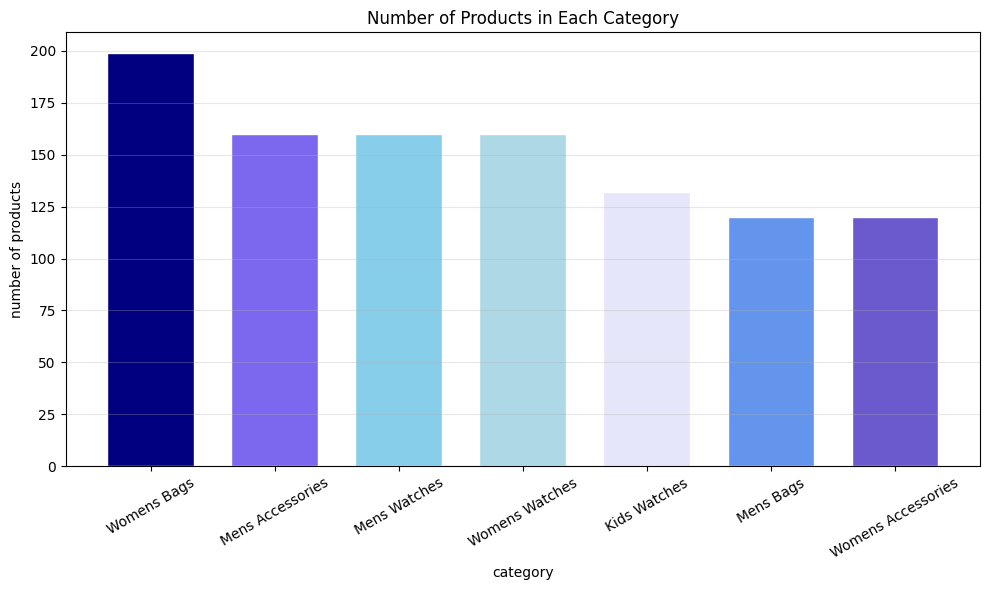

In [143]:
counts = df["Category"].value_counts()

plt.figure(figsize=(10, 6))
plt.bar(counts.index, counts.values,
        color=["navy", "mediumslateblue", "skyblue", "lightblue", "lavender", "cornflowerblue", "slateblue"],
        edgecolor="white",
        width=0.7)
plt.title("Number of Products in Each Category")
plt.xlabel("category")
plt.ylabel("number of products")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Womens Bags has the most product records at 199. Kids Watches falls to 132 after repeated product links are removed. A bar chart is appropriate because the question is a comparison of category counts.

**2. which category is most expensive**

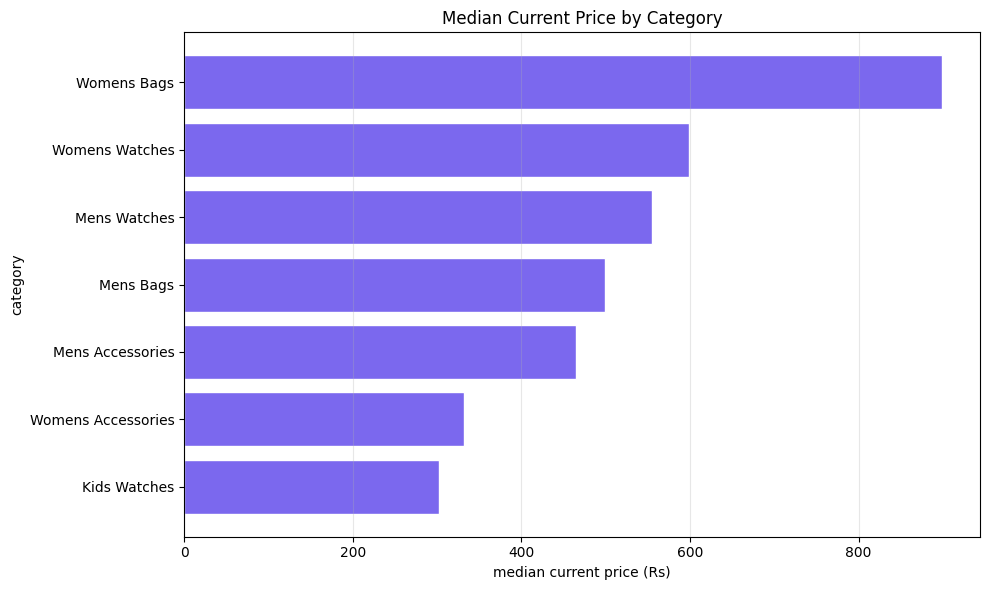

In [144]:
prices = df.groupby("Category")["Current Price"].median().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(prices.index, prices.values,
         color="mediumslateblue",
         edgecolor="white")
plt.title("Median Current Price by Category")
plt.xlabel("median current price (Rs)")
plt.ylabel("category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Womens Bags has the highest median current price at **Rs 899**, while Kids Watches has the lowest at about **Rs 302.5**. We use the median rather than the mean because the price distribution is strongly right-skewed.

**3. the three price groups**

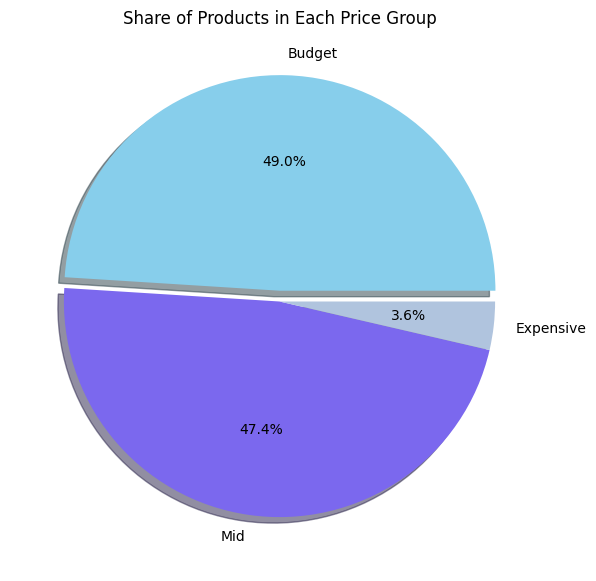

In [145]:
groups = df["Price Group"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(groups.values,
        labels=groups.index,
        colors=["skyblue", "mediumslateblue", "lightsteelblue"],
        autopct="%1.1f%%",
        explode=[0.05, 0, 0],
        shadow=True,
        textprops={"color": "black"})
plt.title("Share of Products in Each Price Group")
plt.show()

About half of the cleaned product records are below Rs 500, while only a small share is Rs 2000 or more. The pie chart is used only because these three price groups are mutually exclusive parts of the same dataset.

**4. what the prices look like overall**

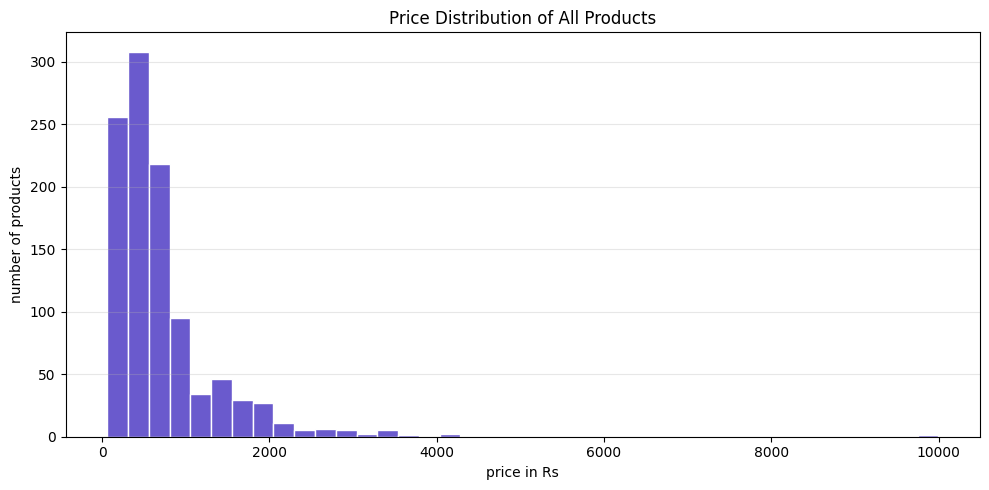

In [146]:
plt.figure(figsize=(10, 5))
plt.hist(df["Current Price"], bins=40,
         color="slateblue",
         edgecolor="white")
plt.title("Price Distribution of All Products")
plt.xlabel("price in Rs")
plt.ylabel("number of products")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Most prices are concentrated toward the lower end, with a long right tail created by a small number of expensive products. This visual explains why the mean price is higher than the median and supports our decision to use medians for category comparisons.

**5. what actually sells**

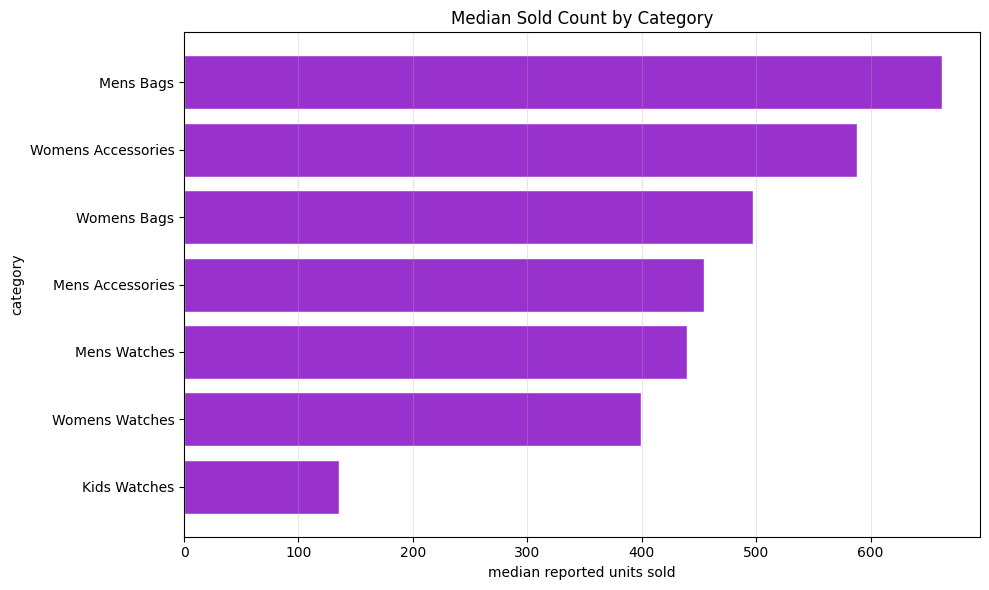

In [147]:
sold = df.groupby("Category")["Sold Count"].median().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(sold.index, sold.values,
         color="darkorchid",
         edgecolor="white")
plt.title("Median Sold Count by Category")
plt.xlabel("median reported units sold")
plt.ylabel("category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Mens Bags has the highest median reported sold count at **662.5**, while Kids Watches has the lowest at **135**. Kids Watches is also the cheapest category, so the category comparison does not support the idea that lower price automatically means higher sales.

**6. average star rating by category**

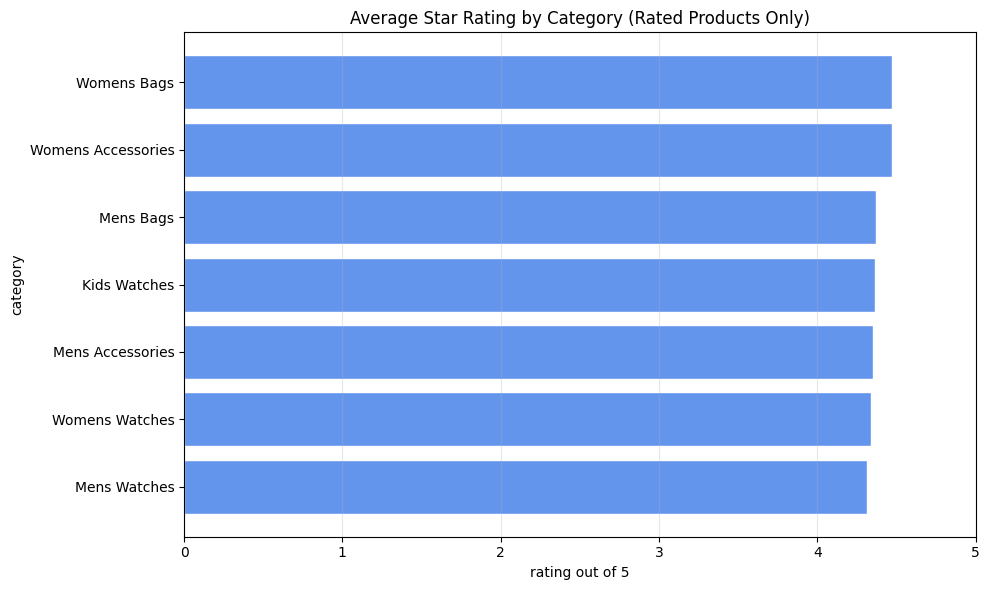

In [148]:
ratings = df.groupby("Category")["Rating in Stars"].mean().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(ratings.index, ratings.values,
         color="cornflowerblue",
         edgecolor="white")
plt.title("Average Star Rating by Category (Rated Products Only)")
plt.xlabel("rating out of 5")
plt.ylabel("category")
plt.xlim(0, 5)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

After treating unrated products as missing rather than as 0-star reviews, every category still has a high average rating, roughly between **4.32 and 4.47**. The differences are small. Keeping the x-axis at the full 0-to-5 scale avoids exaggerating a difference of only a few tenths of a star.

**7. does price affect how much sells**

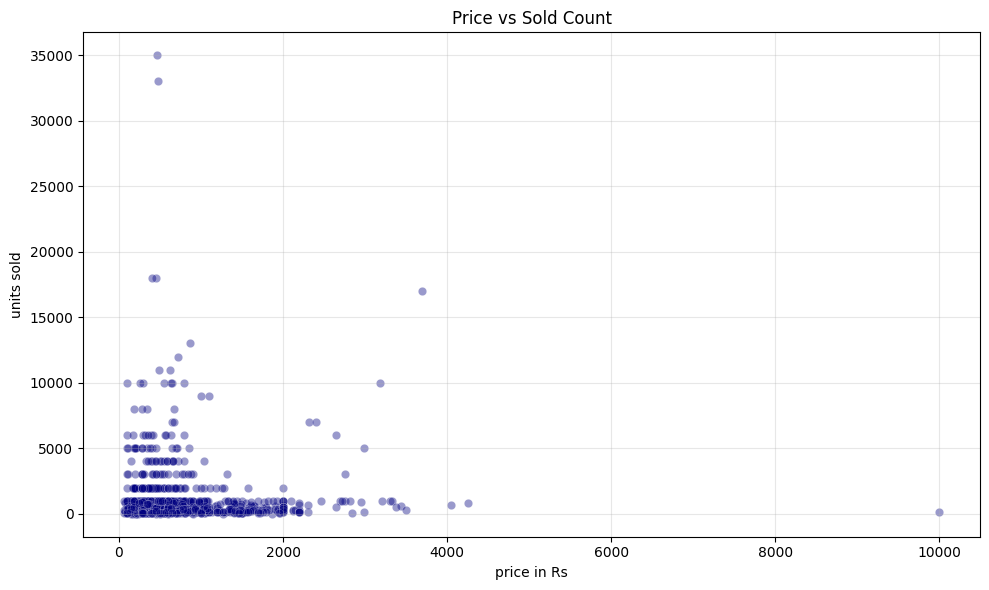

correlation: -0.001


In [149]:
plt.figure(figsize=(10, 6))
plt.scatter(df["Current Price"], df["Sold Count"],
            color="navy",
            alpha=0.4,
            edgecolor="white",
            linewidth=0.3)
plt.title("Price vs Sold Count")
plt.xlabel("price in Rs")
plt.ylabel("units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("correlation:", round(df["Current Price"].corr(df["Sold Count"]), 3))

The scatter plot shows no meaningful linear relationship between current price and reported sold count. The correlation is essentially zero. In this dataset, knowing a product's current price does not help us predict how much it has sold. This is an association result, not a claim that price can never affect demand in other markets or datasets.

**8. rating count and sold count — the strongest relationship**

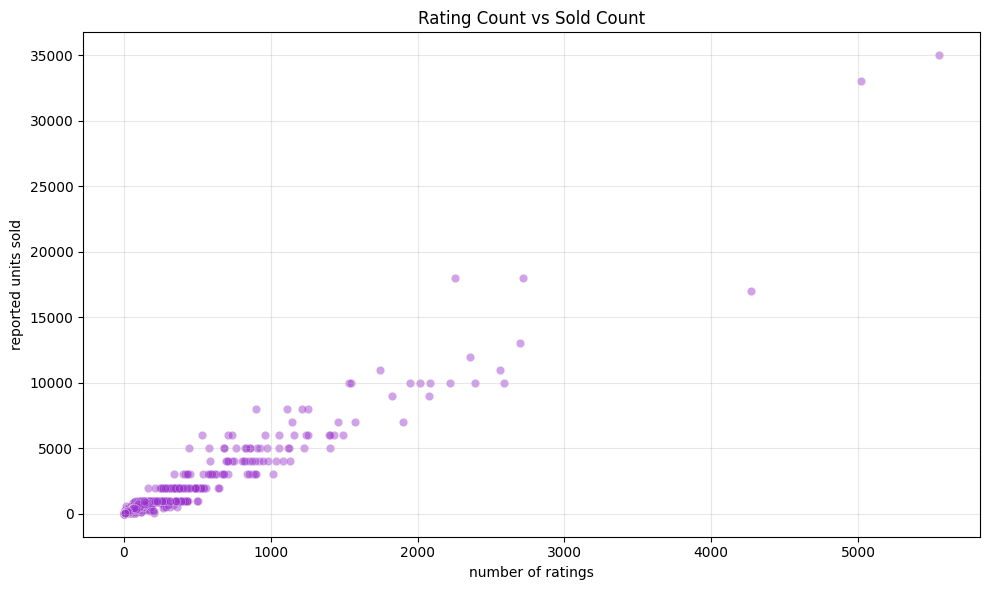

correlation: 0.964


In [150]:
plot_data = df.dropna(subset=["Rating Count", "Sold Count"])

plt.figure(figsize=(10, 6))
plt.scatter(plot_data["Rating Count"], plot_data["Sold Count"],
            color="darkorchid", alpha=0.45,
            edgecolor="white", linewidth=0.3)
plt.title("Rating Count vs Sold Count")
plt.xlabel("number of ratings")
plt.ylabel("reported units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("correlation:", round(plot_data["Rating Count"].corr(plot_data["Sold Count"]), 3))

This is the clearest numerical relationship in the project. Products with more ratings also tend to have much higher reported sold counts. The correlation is very strong, but we should not say ratings **cause** sales: purchases create opportunities for customers to leave ratings, so both variables are also measuring product popularity.

**9. does a larger discount percentage correspond to higher sales?**

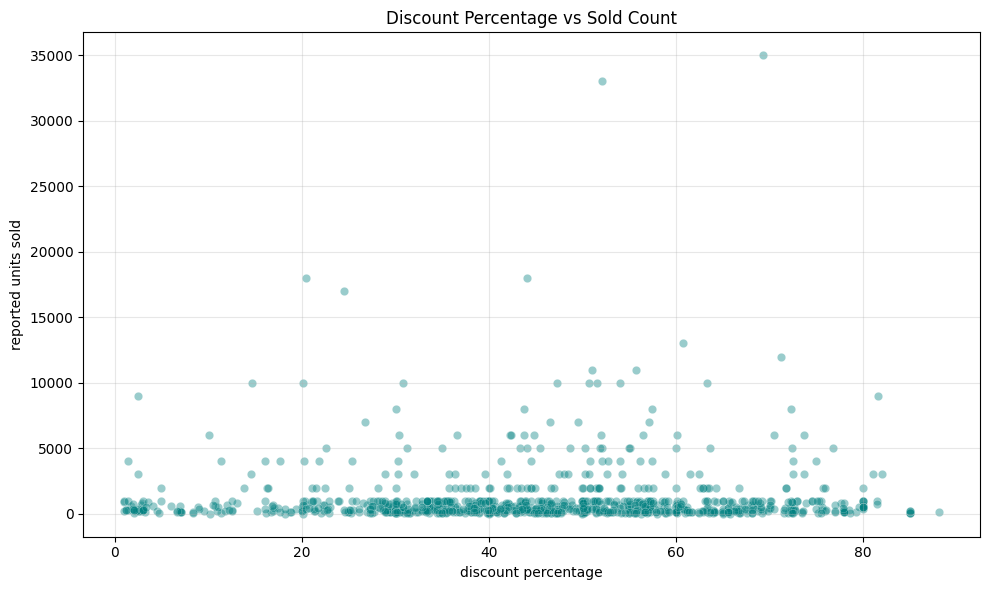

correlation: 0.028


In [151]:
discount_plot = df.dropna(subset=["Discount %", "Sold Count"])

plt.figure(figsize=(10, 6))
plt.scatter(discount_plot["Discount %"], discount_plot["Sold Count"],
            color="teal", alpha=0.4,
            edgecolor="white", linewidth=0.3)
plt.title("Discount Percentage vs Sold Count")
plt.xlabel("discount percentage")
plt.ylabel("reported units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("correlation:", round(discount_plot["Discount %"].corr(discount_plot["Sold Count"]), 3))

The points are widely scattered and the correlation is close to zero. In this dataset, a larger displayed discount percentage is **not strongly associated** with a higher reported sold count. This does not prove discounts are ineffective; we do not know product age, campaign timing, visibility or how long each discount was active.

**10. overall free-delivery and voucher comparison**

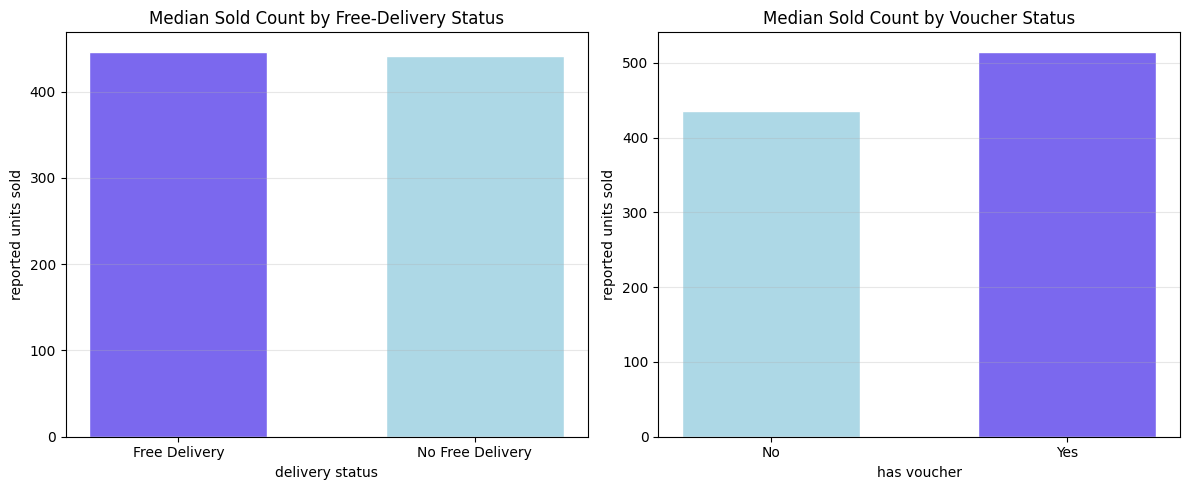

In [152]:
delivery = df.groupby("Delivery")["Sold Count"].median()
voucher = df.groupby("Has Voucher")["Sold Count"].median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.bar(delivery.index, delivery.values, color=["mediumslateblue", "lightblue"], width=0.6, edgecolor="white")
ax1.set_title("Median Sold Count by Free-Delivery Status")
ax1.set_xlabel("delivery status")
ax1.set_ylabel("reported units sold")
ax1.grid(axis="y", alpha=0.3)

ax2.bar(voucher.index, voucher.values, color=["lightblue", "mediumslateblue"], width=0.6, edgecolor="white")
ax2.set_title("Median Sold Count by Voucher Status")
ax2.set_xlabel("has voucher")
ax2.set_ylabel("reported units sold")
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

At the overall level, the free-delivery comparison is almost flat, while the voucher group has a somewhat higher median sold count. These bars are descriptive only: they do not control for category, product age, promotion placement or other factors. The next comparison checks whether the voucher pattern is consistent across categories.

**11. voucher comparison inside each category**

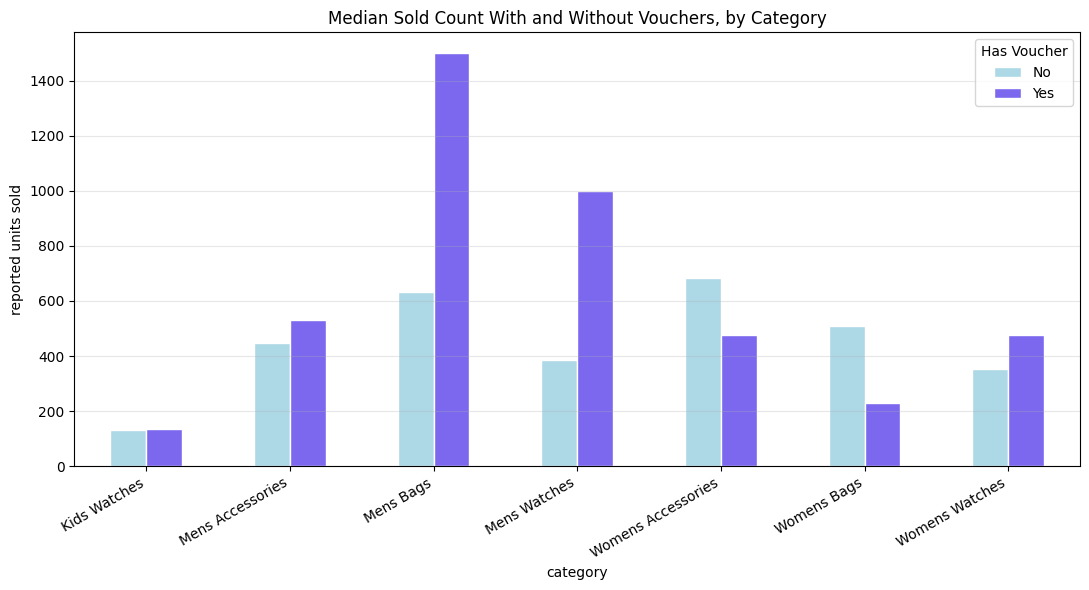

Number of product records in each voucher group:


Has Voucher,No,Yes
Category,,
Kids Watches,125,7
Mens Accessories,147,13
Mens Bags,112,8
Mens Watches,124,36
Womens Accessories,94,26
Womens Bags,182,17
Womens Watches,112,48


In [153]:
voucher_by_category = df.pivot_table(
    index="Category",
    columns="Has Voucher",
    values="Sold Count",
    aggfunc="median"
)

voucher_counts = df.pivot_table(
    index="Category",
    columns="Has Voucher",
    values="Title",
    aggfunc="count",
    fill_value=0
)

voucher_by_category.plot(kind="bar", figsize=(11, 6),
                         color=["lightblue", "mediumslateblue"],
                         edgecolor="white")
plt.title("Median Sold Count With and Without Vouchers, by Category")
plt.xlabel("category")
plt.ylabel("reported units sold")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Has Voucher")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Number of product records in each voucher group:")
voucher_counts

The category-level chart shows why the overall voucher result must be treated carefully. Voucher listings have higher median sold counts in some categories, but lower medians in others. The voucher groups are also much smaller in several categories. Therefore the correct conclusion is **not** “vouchers increase sales”; it is that voucher status is associated with different sales patterns depending on category, and this dataset alone cannot establish a causal effect.

## Course concept checklist

Before the final findings, this is what the notebook has **actually used on the Daraz data**:

- ✅ **File input / output:** CSV loaded with `pd.read_csv()` and cleaned data exported with `to_csv()`
- ✅ **Variables & data types:** DataFrame variables, strings, integers/floats and type conversion
- ✅ **Strings & lists:** text cleaned with string methods; lists collect processed values
- ✅ **Operators:** subtraction, division, multiplication and comparisons
- ✅ **Conditions:** `if`, `elif`, `else`
- ✅ **Loops:** `for` loops over real dataset values/categories
- ✅ **Functions:** reusable cleaning and grouping functions
- ✅ **Pandas:** cleaning, filtering, grouping, aggregation and correlation
- ✅ **NumPy:** arrays, percentiles, IQR, boolean numerical checks and correlation verification
- ✅ **Matplotlib:** multiple chart types with interpretation

This checklist is a map of concepts already demonstrated above; it does not introduce separate example code.

# <div style="text-align:center; border-radius:15px 50px; padding:12px; color:white; margin:0; font-size:150%; font-family:Pacifico; background-color: #4B0082; overflow:hidden"><b>Part 4: findings and conclusion</b><div style="font-family:Arial; font-size:58%; color:#d8dcff; margin-top:8px">presented by Manish</div></div>

## Major findings

The findings below come directly from the cleaned dataset and the outputs above.

**1. Cleaning was necessary before analysis.**  
The raw file has 1078 rows. Using the product link as the listing identifier leaves **1051 product records** after repeated links are removed. Ratings, prices and sold counts required conversion from text. Eleven records have no customer rating yet, so their displayed `0` rating is treated as missing rather than as a real 0-star review.

**2. Womens Bags is the largest and most expensive category in this dataset.**  
It has **199 product records** and a median current price of **Rs 899**. Kids Watches has the lowest median price at about **Rs 302.5**.

**3. Prices are strongly right-skewed.**  
The overall median current price is **Rs 525**, while the mean is about **Rs 706**. A small number of expensive products pull the mean upward, so the median is more representative for category comparisons.

**4. Mens Bags has the highest typical sold count; Kids Watches has the lowest.**  
Mens Bags has a median reported sold count of **662.5**, compared with **135** for Kids Watches. The cheapest category is therefore not the strongest-selling category in this snapshot.

**5. Current price has almost no linear relationship with sold count.**  
The Pearson correlation is approximately **-0.001**, which is effectively zero for this analysis. The scatter plot also shows no meaningful pattern between price and reported units sold.

**6. Rating volume is much more informative than rating score.**  
`Rating Count` has a very strong positive correlation with `Sold Count` of about **0.964**, while the star rating itself has only a weak relationship with sold count. This should be interpreted as a popularity/engagement association, not as proof that ratings cause sales.

**7. Larger displayed discounts are not strongly associated with higher sold counts.**  
The correlation between `Discount %` and `Sold Count` is close to zero. This snapshot does not show a simple “bigger discount = more sales” pattern.

**8. Offer effects are mixed rather than universal.**  
Free-delivery and no-free-delivery listings have very similar overall median sold counts. Voucher listings have a higher overall median, but the category-level chart shows that the direction changes between categories. We therefore describe vouchers and delivery as associations rather than causes.

## Limitations

* The dataset is a **snapshot**, so it does not show how prices, promotions or sales changed over time.
* `Sold Count` is a marketplace-reported value and some records are missing it. Values written with `K` may also be rounded by the marketplace display.
* Repeated product links sometimes contain slightly different values, but there is no timestamp to identify which version is newest. We keep the first record consistently to avoid double-counting a listing.
* Voucher formats are mixed, so we reduce them to **Yes/No** rather than pretending rupee, percentage and voucher-count offers are directly comparable.
* The dataset does not include important possible sales drivers such as product age, ad placement, seller reputation, traffic, campaign timing or inventory.
* Because this is observational data, correlations and group differences show **association, not causation**.

## Summary and conclusion

We analysed a 2024 snapshot of Daraz Pakistan watches, bags and accessories. The project uses the Python concepts from class as part of one continuous analysis: CSV file input/output, data types, string cleaning, lists, arithmetic operators, conditions, functions, loops, pandas grouping, **NumPy numerical analysis** and Matplotlib visualization.

The biggest technical task was turning the raw marketplace text into usable numerical data. After cleaning and removing repeated product links, **1051 product records** remained for analysis. The price distribution is strongly right-skewed, so medians are more useful than means for typical prices and sold counts.

The category analysis shows that Womens Bags is the largest and highest-priced category, while Mens Bags has the highest median reported sold count. The relationship analysis adds an important result: **current price, star rating and discount percentage are weakly related to sold count, while rating count is very strongly associated with sold count**. Rating count should be treated as an indicator of product popularity/engagement, not as a cause of sales.

The offer analysis is also more nuanced than a simple yes/no conclusion. Free delivery shows little overall difference, and voucher listings have a higher overall median sold count, but the category-level result changes direction between categories. That is why the notebook avoids claiming that vouchers or delivery directly increase sales.

Overall, the main lesson from the project is that meaningful data analysis requires more than making graphs. We first had to understand the raw data, clean it carefully, choose appropriate summary statistics, compare groups, use NumPy and pandas to examine numerical relationships, visualize those relationships and then state conclusions only as strongly as the dataset supports.